In [3]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Ansatz Circuit Structure:
     ┌──────────┐                 
q_0: ┤ Ry(θ[0]) ├──■──────────────
     └──────────┘┌─┴─┐┌──────────┐
q_1: ────────────┤ X ├┤ Ry(θ[1]) ├
                 └───┘└──────────┘

Running VQE Optimization...

Optimization Results Verification
VQE 에너지        : -1.50000000
정확한 최소 에너지 : -1.50000000
절대 오차         : 5.773e-15
검증 통과: VQE가 정확한 최솟값을 성공적으로 찾아냈습니다.


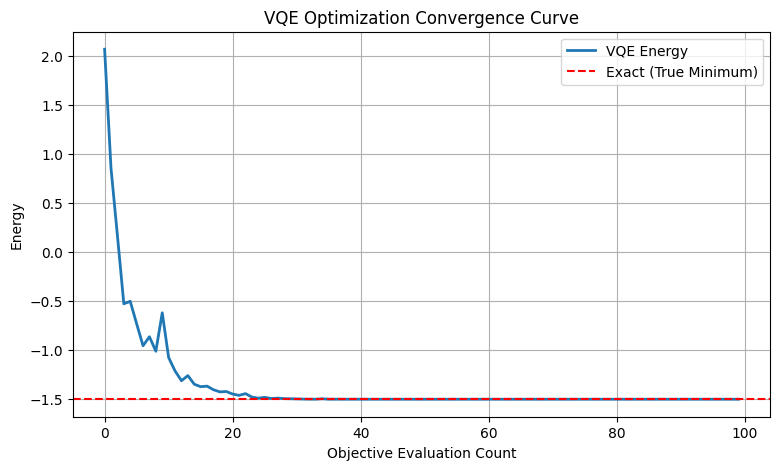

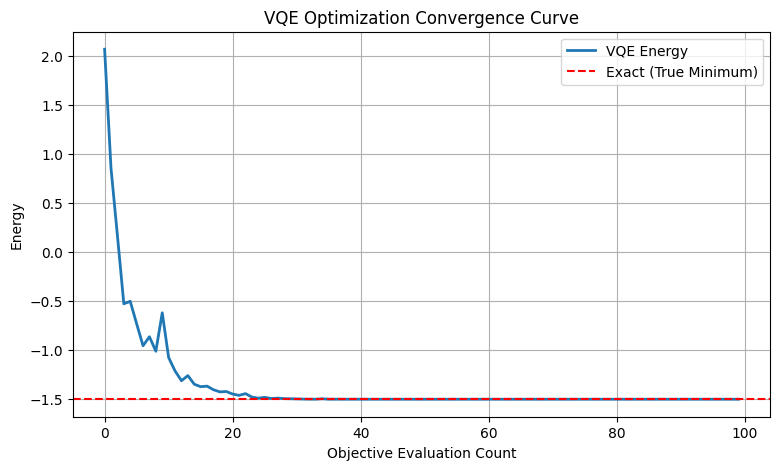

In [5]:
%matplotlib inline

# Qiskit 핵심 컴포넌트, 해밀턴산 연산자, CPU 시뮬레이터(StatevectorEstimator),
# 그리고 VQE 알고리즘과 고전 최적화기(COBYLA)를 불러옵니다.
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA

# 양자 시스템이 가진 에너지 상태를 표현하는 연산자(Hamiltonian)를 정의합니다.
# 여기서는 ZI, IZ, ZZ 파울리 연산자의 선형 결합으로 구성된 2큐비트 모델을 사용합니다.
H = SparsePauliOp.from_list([
    ("ZI", 1.0),
    ("IZ", 1.0),
    ("ZZ", 0.5)
])

# 최적화 과정에서 조정될 파라미터 벡터(θ, 총 2개)를 생성하고,
# RY 게이트와 CNOT 게이트를 조합하여 양자 상태를 변형하는 변분 회로(Ansatz)를 설계합니다.
theta = ParameterVector("θ", 2)

ansatz = QuantumCircuit(2)
ansatz.ry(theta[0], 0)
ansatz.cx(0, 1)
ansatz.ry(theta[1], 1)

# 회로 구조 시각화 확인
print("=" * 60)
print("Ansatz Circuit Structure:")
print("=" * 60)
print(ansatz.draw(output="text"))

# VQE 최적화 과정에서 매 스텝마다 계산되는 에너지(value)를 실시간으로 수집하여
# 학습 곡선(Energy Convergence Curve)을 그릴 수 있도록 리스트에 저장합니다.
history = []

def callback_fn(count, params, value, meta):
    """
    VQE 최적화 루프 안에서 매번 호출되는 콜백 함수
    - count : 최적화 평가 횟수
    - params: 현재 파라미터 값
    - value : 현재 스텝에서 계산된 에너지(Loss)
    - meta  : 추가 메타데이터
    """
    history.append(float(value))

# 최적화
# - StatevectorEstimator: CPU 상에서 이상적인 양자 상태의 기댓값을 정밀하게 계산
# - COBYLA: 미분값 없이 에너지를 줄여나가는 블랙박스 고전 최적화 알고리즘
# - initial_point: 파라미터의 초기 시작값 [0.3, 0.7]
vqe = VQE(
    estimator=StatevectorEstimator(seed=42),
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=300, tol=1e-7), # 300회 반복으로 최적화
    initial_point=[0.3, 0.7],
    callback=callback_fn
)

# 정의한 해밀턴산(H)을 대상으로 VQE 최적화를 실행하여
# 시스템이 가질 수 있는 최저 에너지 상태(Ground State Energy)를 찾습니다.
print("\n" + "=" * 60)
print("Running VQE Optimization...")
print("=" * 60)

result = vqe.compute_minimum_eigenvalue(H)

# 행렬 고유값 분석(Linear Algebra)을 통해 이론적인 정확한 최소 에너지(Exact)를 구하고,
# VQE가 찾아낸 에너지와 비교하여 오차를 검증합니다.
exact = float(np.linalg.eigvalsh(H.to_matrix())[0])
energy = float(result.eigenvalue.real)
absolute_error = abs(energy - exact)

print("\n" + "=" * 60)
print("Optimization Results Verification")
print("=" * 60)
print(f"VQE 에너지        : {energy:.8f}")
print(f"정확한 최소 에너지 : {exact:.8f}")
print(f"절대 오차         : {absolute_error:.3e}")

# 오차가 허용 범위 내인지 엄격하게 검증
assert absolute_error < 1e-4, "오차가 허용 범위를 초과했습니다!"
print("검증 통과: VQE가 정확한 최솟값을 성공적으로 찾아냈습니다.")

# 최적화 평가 횟수에 따른 에너지 감소 추이를 그래프로 시각화합니다.
fig = plt.figure(figsize=(9, 5))

plt.plot(history, label="VQE Energy", linewidth=2)
plt.axhline(exact, color="red", linestyle="--", label="Exact (True Minimum)")

plt.xlabel("Objective Evaluation Count")
plt.ylabel("Energy")
plt.title("VQE Optimization Convergence Curve")
plt.grid(True)
plt.legend()

display(fig)
plt.show()